In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report

Chargement des données et des classes\
Les étiquettes de 0 à 9 correspondent aux vêtements.

In [3]:
(X_train_raw, y_train), (X_test_raw, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print(X_train_raw.shape, y_train.shape)

classes = ["T-shirt/top", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Sneaker", "Sac", "Bottine"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (60000,)


Prétraitement (Normalisation et Canal)\
Exactement comme MNIST, on passe les pixels de [0, 255] à [0, 1] et on ajoute le canal de couleur pour les convolutions.

In [4]:
# Normalisation (0 à 1)
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

# Ajout du canal : (N, 28, 28) devient (N, 28, 28, 1)
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print("Formes finales :", X_train.shape, X_test.shape)

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


Architecture du CNN\
On reprend la même architecture performante que dans l'Exercice 3.

In [5]:
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

Entraînement du modèle

In [6]:
# La validation est prise dans le train pour ne pas toucher au test final
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 52ms/step - accuracy: 0.7578 - loss: 0.6587 - val_accuracy: 0.8437 - val_loss: 0.4080
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 94s 67ms/step - accuracy: 0.8518 - loss: 0.4085 - val_accuracy: 0.8743 - val_loss: 0.3345
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 52ms/step - accuracy: 0.8760 - loss: 0.3460 - val_accuracy: 0.8893 - val_loss: 0.2992
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.8894 - loss: 0.3129 - val_accuracy: 0.8952 - val_loss: 0.2831
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 50ms/step - accuracy: 0.8962 - loss: 0.2846 - val_accuracy: 0.8982 - val_loss: 0.2671


Évaluation et matrice de confusion\
Cette cellule va afficher la heatmap (carte de chaleur) qui permet de repérer quelles classes le réseau confond le plus

313/313 - 3s - 9ms/step - accuracy: 0.8954 - loss: 0.2838

Précision sur le test : 89.54%
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


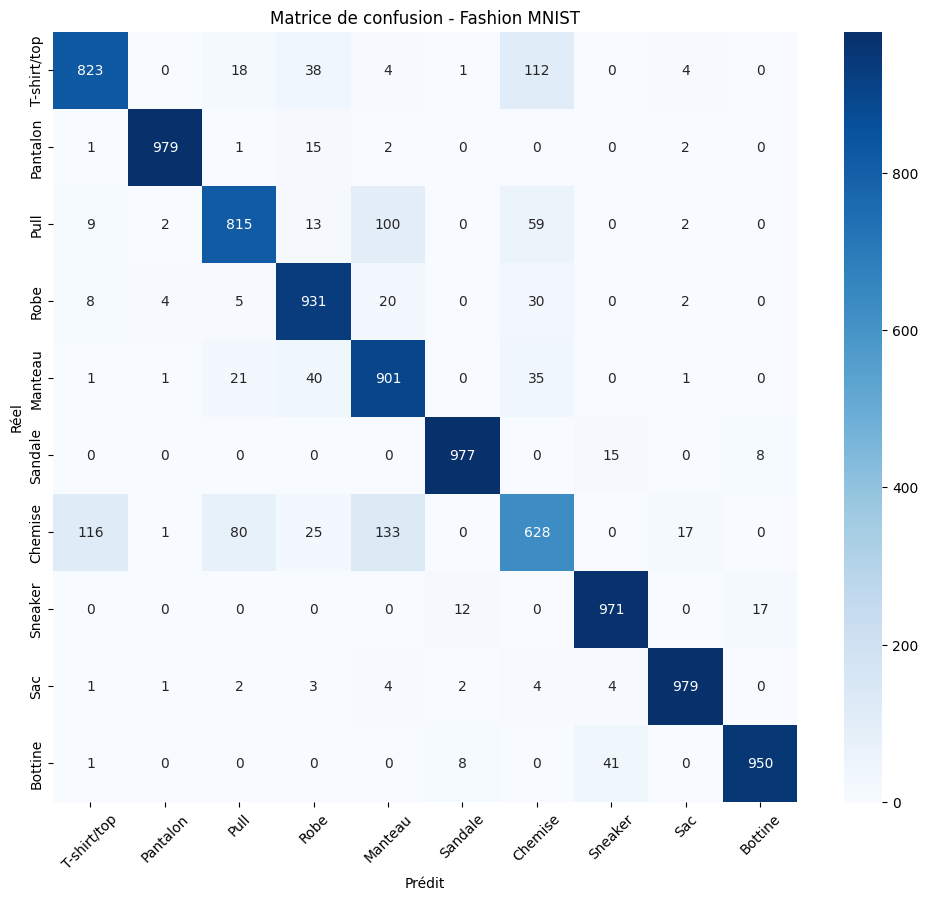

              precision    recall  f1-score   support

 T-shirt/top       0.86      0.82      0.84      1000
    Pantalon       0.99      0.98      0.98      1000
        Pull       0.87      0.81      0.84      1000
        Robe       0.87      0.93      0.90      1000
     Manteau       0.77      0.90      0.83      1000
     Sandale       0.98      0.98      0.98      1000
     Chemise       0.72      0.63      0.67      1000
     Sneaker       0.94      0.97      0.96      1000
         Sac       0.97      0.98      0.98      1000
     Bottine       0.97      0.95      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.89     10000
weighted avg       0.90      0.90      0.89     10000



In [7]:
# Évaluation
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test : {acc * 100:.2f}%")

# Prédictions
y_pred = np.argmax(model.predict(X_test), axis=1)

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion - Fashion MNIST")
plt.xticks(rotation=45)
plt.show()

# Rapport détaillé
print(classification_report(y_test, y_pred, target_names=classes))

Affichage visuel d'une prédiction\
On vérifie sur la première image du test.

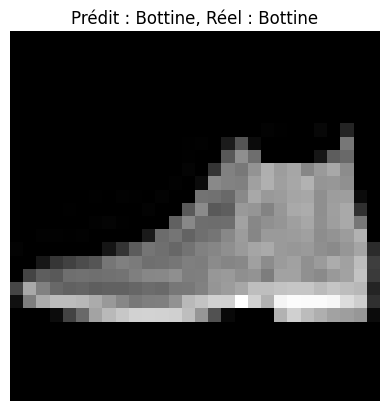

In [8]:
# Affichage de la première image
plt.imshow(X_test_raw[0], cmap="gray")
titre = f"Prédit : {classes[y_pred[0]]}, Réel : {classes[y_test[0]]}"
plt.title(titre)
plt.axis('off')
plt.show()

En conclusion , nous pouvons en déduire que la classe "Chemise" est la plus difficile à prédire : sur la ligne "Chemise", on voit que le réseau n'a vu juste que 628 fois. Il l'a très souvent confondue avec les manteaux (133 fois, colonne 4), les T-shirts/tops (116 fois, colonne 0) et les pulls (80 fois, colonne 2). \
  Les "pulls" et les "manteaux" se ressemblent : sur la ligne "Pull", le réseau s'est trompé 100 fois en prédisant un manteau. \
   L'explication est simple : dans des images très basse résolution (28x28 pixels) et en nuances de gris, un pull, une chemise et un manteau partagent quasiment la même silhouette globale. \
    Le réseau a donc logiquement du mal à les différencier, contrairement aux pantalons ou aux chaussures qui ont des scores d'exactitude très élevés (proches de 1000).